# Entrenamiento con descriptores clásicos

1. **Experimento 1:** comparar características (píxeles + PCA, HOG, LBP y HOG+LBP) con validación cruzada estratificada de 5 particiones sobre train.
2. **Experimento 2:** con las mejores características, comparar SVM lineal y SVM RBF.
3. **Evaluación:** entrenar el modelo elegido con todo train y evaluarlo una sola vez en test.
4. **Guardar** el modelo para el prototipo.

El conjunto de test no se usa para elegir nada, solo para la evaluación final.

In [ ]:
import os, sys
from pathlib import Path

# Los notebooks están en notebooks/, se trabaja desde la carpeta del proyecto
if not Path("emociones_utils.py").exists():
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time
import numpy as np
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from emociones_utils import CLASES, NOMBRE_ES, extraer

CACHE_IMAGENES = "data/fer6_preprocesado.npz"
CACHE_CARACT = "data/fer6_caracteristicas.npz"
RUTA_MODELO = "modelos/modelo_emociones.joblib"

K_FOLDS = 5
SUBMUESTRA_RBF = 10000   # la SVM RBF es lenta, el experimento 2 se hace con una submuestra
SEMILLA = 0

NOMBRES = [NOMBRE_ES[c] for c in CLASES]
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## Datos

In [3]:
img = np.load(CACHE_IMAGENES)
car = np.load(CACHE_CARACT)
y_train, y_test = img["y_train"], img["y_test"]

CARACT = {
    "pixeles": (img["X_train"].reshape(len(y_train), -1) / 255.0, img["X_test"].reshape(len(y_test), -1) / 255.0),
    "hog":     (car["hog_train"], car["hog_test"]),
    "lbp":     (car["lbp_train"], car["lbp_test"]),
}
CARACT["hog+lbp"] = (np.hstack([CARACT["hog"][0], CARACT["lbp"][0]]),
                     np.hstack([CARACT["hog"][1], CARACT["lbp"][1]]))

for k, (tr, te) in CARACT.items():
    print(f"{k:8s} train {tr.shape}  test {te.shape}")

pixeles  train (28273, 2304)  test (7067, 2304)
hog      train (28273, 900)  test (7067, 900)
lbp      train (28273, 360)  test (7067, 360)
hog+lbp  train (28273, 1260)  test (7067, 1260)


## Métricas y modelos
Como las clases están desequilibradas, la métrica principal es el **F1 macro** (media del F1 de cada clase, todas con el mismo peso). También se muestra la accuracy.

Los modelos se definen como `Pipeline` (escalado → PCA → clasificador) para que en la validación cruzada el escalado y el PCA se ajusten solo con la parte de entrenamiento de cada partición. Con `class_weight="balanced"` la SVM da más peso a las clases con menos imágenes.

In [4]:
def svm_lineal(pca=False):
    pasos = [("escalar", StandardScaler())]
    if pca:
        pasos.append(("pca", PCA(0.95, random_state=SEMILLA)))
    pasos.append(("svm", LinearSVC(C=0.01, class_weight="balanced", dual=False, max_iter=5000)))
    return Pipeline(pasos)

def knn_pca():
    return Pipeline([("pca", PCA(0.95, random_state=SEMILLA)),
                     ("knn", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))])

def svm_rbf():
    return Pipeline([("escalar", StandardScaler()),
                     ("pca", PCA(0.95, random_state=SEMILLA)),
                     ("svm", SVC(kernel="rbf", C=5, gamma="scale", class_weight="balanced"))])

kfold = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEMILLA)

def evaluar_cv(nombre, modelo, X, y):
    t0 = time.time()
    r = cross_validate(modelo, X, y, cv=kfold, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    fila = {"experimento": nombre,
            "acc": r["test_accuracy"].mean(), "acc_std": r["test_accuracy"].std(),
            "f1": r["test_f1_macro"].mean(), "f1_std": r["test_f1_macro"].std(),
            "seg": time.time() - t0}
    print(f"{nombre:28s} acc={fila['acc']:.3f}±{fila['acc_std']:.3f}  "
          f"F1macro={fila['f1']:.3f}±{fila['f1_std']:.3f}  ({fila['seg']:.0f} s)")
    return fila

## Experimento 1: características

In [5]:
experimentos_1 = [
    ("Píxeles + PCA + KNN",      knn_pca(),             "pixeles"),
    ("Píxeles + PCA + SVM lin.", svm_lineal(pca=True),  "pixeles"),
    ("HOG + SVM lin.",           svm_lineal(),          "hog"),
    ("LBP + SVM lin.",           svm_lineal(),          "lbp"),
    ("HOG+LBP + SVM lin.",       svm_lineal(),          "hog+lbp"),
]

resultados_1 = []
for nombre, modelo, tipo in experimentos_1:
    fila = evaluar_cv(nombre, modelo, CARACT[tipo][0], y_train)
    fila["caract"] = tipo
    resultados_1.append(fila)

Píxeles + PCA + KNN          acc=0.361±0.002  F1macro=0.348±0.004  (107 s)
Píxeles + PCA + SVM lin.     acc=0.358±0.003  F1macro=0.321±0.004  (158 s)
HOG + SVM lin.               acc=0.433±0.004  F1macro=0.401±0.004  (184 s)
LBP + SVM lin.               acc=0.355±0.006  F1macro=0.324±0.006  (16 s)
HOG+LBP + SVM lin.           acc=0.454±0.003  F1macro=0.424±0.003  (252 s)


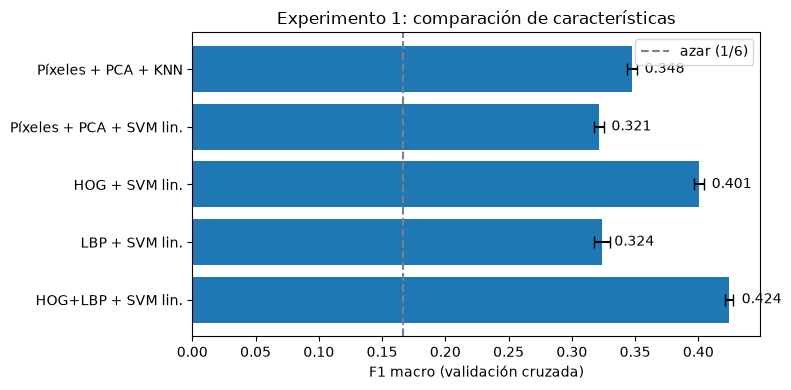

Mejores características con SVM: hog+lbp


In [6]:
def grafico(resultados, titulo):
    nombres = [r["experimento"] for r in resultados]
    f1 = [r["f1"] for r in resultados]
    err = [r["f1_std"] for r in resultados]
    plt.figure(figsize=(8, 0.6 * len(nombres) + 1))
    plt.barh(nombres, f1, xerr=err, capsize=4)
    for i, v in enumerate(f1):
        plt.text(v + 0.01, i, f"{v:.3f}", va="center")
    plt.axvline(1 / len(CLASES), ls="--", c="gray", label="azar (1/6)")
    plt.xlabel("F1 macro (validación cruzada)")
    plt.title(titulo); plt.legend(); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

grafico(resultados_1, "Experimento 1: comparación de características")

mejor_1 = max([r for r in resultados_1 if "SVM" in r["experimento"]], key=lambda r: r["f1"])
MEJOR_CARACT = mejor_1["caract"]
print("Mejores características con SVM:", MEJOR_CARACT)

## Experimento 2: SVM lineal frente a SVM RBF
La SVM RBF permite fronteras no lineales pero su coste crece mucho con el número de muestras, así que la comparación se hace sobre una submuestra estratificada de 10.000 imágenes (las mismas para los dos modelos).

Submuestra: 10000 imágenes, características 'hog+lbp'
hog+lbp + SVM lineal         acc=0.419±0.010  F1macro=0.395±0.011  (69 s)
hog+lbp + PCA + SVM RBF      acc=0.503±0.005  F1macro=0.482±0.008  (97 s)


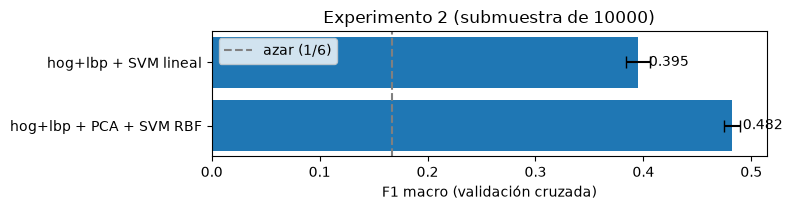

In [7]:
X_mejor = CARACT[MEJOR_CARACT][0]
n_sub = min(SUBMUESTRA_RBF, len(y_train))
if n_sub < len(y_train):
    idx_sub, _ = train_test_split(np.arange(len(y_train)), train_size=n_sub,
                                  stratify=y_train, random_state=SEMILLA)
else:
    idx_sub = np.arange(len(y_train))
print(f"Submuestra: {len(idx_sub)} imágenes, características '{MEJOR_CARACT}'")

resultados_2 = [
    evaluar_cv(f"{MEJOR_CARACT} + SVM lineal", svm_lineal(), X_mejor[idx_sub], y_train[idx_sub]),
    evaluar_cv(f"{MEJOR_CARACT} + PCA + SVM RBF", svm_rbf(), X_mejor[idx_sub], y_train[idx_sub]),
]
grafico(resultados_2, f"Experimento 2 (submuestra de {len(idx_sub)})")

## Modelo final
Se elige el que tenga mejor F1 macro en el experimento 2.

In [8]:
ELECCION = "rbf" if resultados_2[1]["f1"] > resultados_2[0]["f1"] else "lineal"
modelo_final = svm_rbf() if ELECCION == "rbf" else svm_lineal()
print(f"Modelo final: {MEJOR_CARACT} + SVM {ELECCION}")

Modelo final: hog+lbp + SVM rbf


## Evaluación en test

In [9]:
X_tr, X_te = CARACT[MEJOR_CARACT]

t0 = time.time()
modelo_final.fit(X_tr, y_train)
t_entreno = time.time() - t0

y_pred = modelo_final.predict(X_te)
acc = accuracy_score(y_test, y_pred)
f1m = f1_score(y_test, y_pred, average="macro")
print(f"Entrenamiento: {t_entreno:.0f} s")
print(f"TEST -> accuracy = {acc:.3f}   F1 macro = {f1m:.3f}\n")
print(classification_report(y_test, y_pred, target_names=NOMBRES, digits=3))

Entrenamiento: 1675 s
TEST -> accuracy = 0.569   F1 macro = 0.554

              precision    recall  f1-score   support

      enfado      0.468     0.449     0.458       958
       miedo      0.484     0.401     0.439      1024
       feliz      0.695     0.793     0.741      1774
     neutral      0.519     0.517     0.518      1233
      triste      0.434     0.452     0.443      1247
    sorpresa      0.767     0.690     0.726       831

    accuracy                          0.569      7067
   macro avg      0.561     0.550     0.554      7067
weighted avg      0.565     0.569     0.566      7067



## Matriz de confusión
Normalizada por filas: la diagonal es el recall de cada clase.

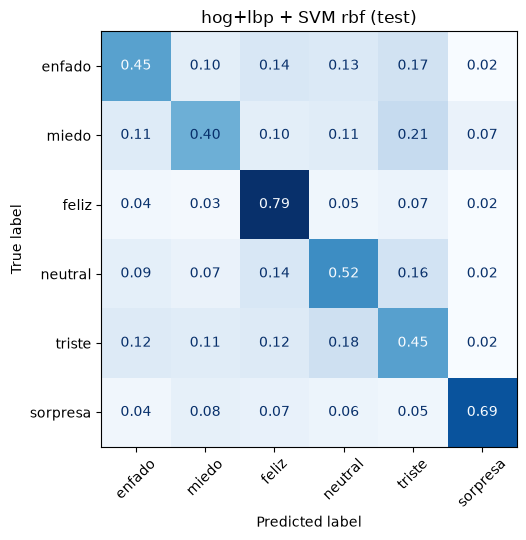

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=NOMBRES,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{MEJOR_CARACT} + SVM {ELECCION} (test)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Tiempo de predicción
Tiempo por imagen (extraer características + predecir), para ver si se puede usar en tiempo real.

In [11]:
muestras = img["X_test"][:200]
t0 = time.time()
for m in muestras:
    modelo_final.predict(extraer(m, MEJOR_CARACT)[None, :])
ms = 1000 * (time.time() - t0) / len(muestras)
print(f"Tiempo por imagen (características + predicción): {ms:.2f} ms")

Tiempo por imagen (características + predicción): 48.22 ms


## Guardar el modelo
Se guarda el pipeline completo junto con el tipo de características, el orden de las clases y la versión de scikit-learn.

In [12]:
Path(RUTA_MODELO).parent.mkdir(exist_ok=True)
paquete = {
    "modelo": modelo_final,
    "caract": MEJOR_CARACT,
    "clases": CLASES,
    "sklearn": sklearn.__version__,
    "test_accuracy": acc,
    "test_f1_macro": f1m,
    "ms_por_imagen": ms,
}
joblib.dump(paquete, RUTA_MODELO)
print("Modelo guardado en", RUTA_MODELO)

# Comprobación: cargar y predecir una imagen
p = joblib.load(RUTA_MODELO)
pred = p["modelo"].predict(extraer(img["X_test"][0], p["caract"])[None, :])[0]
print("Prueba de carga -> predicción:", NOMBRE_ES[p["clases"][pred]], "| real:", NOMBRE_ES[CLASES[y_test[0]]])

Modelo guardado en modelos/modelo_emociones.joblib
Prueba de carga -> predicción: enfado | real: enfado


El archivo ocupaba 109 MB, más del límite de GitHub, así que se vuelve a guardar comprimido.

In [13]:
p = joblib.load(RUTA_MODELO)
joblib.dump(p, RUTA_MODELO, compress=3)
print(f"{Path(RUTA_MODELO).stat().st_size / 1e6:.0f} MB")

66 MB


## Resultados

| Experimento | F1 macro (CV) |
|---|---|
| Píxeles + PCA + KNN | 0,348 |
| Píxeles + PCA + SVM lineal | 0,321 |
| LBP + SVM lineal | 0,324 |
| HOG + SVM lineal | 0,401 |
| HOG+LBP + SVM lineal | 0,424 |

- Los descriptores funcionan mejor que los píxeles, y HOG bastante mejor que LBP: para la emoción importa más la forma de boca y cejas que la textura. Juntos mejoran a cada uno por separado.
- Con la misma submuestra, la SVM RBF (0,482) supera en casi 9 puntos a la lineal (0,395).
- En test el modelo final obtiene **F1 macro 0,554** y accuracy 0,569. Es más que en la validación cruzada porque el modelo final se entrena con 28.273 imágenes en lugar de 8.000.
- Feliz (0,79) y sorpresa (0,69) son las mejor reconocidas; miedo (0,40), enfado y triste (0,45) las peores. Neutral y triste se confunden entre sí, y miedo se va sobre todo a triste.
- Tarda unos 48 ms por imagen, demasiado para predecir en todos los frames, por lo que en el prototipo se predice cada pocos frames.